# APRAU 2026/2027 — Group 26
## Exploratory analysis, regression, classification, resampling and regularization

**Students:** 1131504 · 1250515 · 1220638  
**Repository:** [LadyCiaradh/APRAU_1131504_1250515_1220638](https://github.com/LadyCiaradh/APRAU_1131504_1250515_1220638)  
**Dataset:** `dataset_grupo_26.csv`  
**Course:** Aprendizagem Automática — Mestrado em Engenharia Informática, ISEP

### Executive overview
This notebook implements the five technical sections of the official APRAU assignment: exploratory data analysis; simple and multiple linear regression; classification with Logistic Regression and Linear Discriminant Analysis; resampling with holdout, 5-fold, 10-fold, leave-one-out and bootstrap; and regularization-based classification feature selection with L1/L2 penalties.

Two supervised prediction tasks are studied independently: (i) a continuous laboratory measurement (`target_regression`), and (ii) a three-category diagnosis (`target_class`). **These targets are never used as predictors of one another**, because using a label at prediction time may be unrealistic and could leak outcome information. Each section first describes the methodological decisions, then shows executable results, and finally interprets those results.

**Interpretation scope:** associations in this dataset are not causal effects and cannot establish clinical utility. The diagnostic abbreviations and physical units of the regression outcome are not formally expanded in the supplied assignment, so we retain the original label names and target units.

## 0. Reproducibility and computational environment

**Approach.** We use `pandas` and `numpy` for data handling, `matplotlib`/`seaborn` for visual exploration, and `scikit-learn` for models and evaluation. A fixed random seed permits reproducible splits. All imputation, one-hot encoding, scaling and supervised feature selection required during model fitting are included inside pipelines, avoiding validation/test leakage. The notebook runs from either the repository root or the `notebooks/` subdirectory.

**Run instructions:** Install the packages in `requirements.txt`, select the Python kernel in JupyterLab, and use **Run → Run All Cells**. LOOCV deliberately performs many fits; its computation is expensive but required by the assignment.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency
from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     StratifiedShuffleSplit, LeaveOneOut,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 26
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn_version)

Python: 3.13.9 | scikit-learn: 1.9.1


## 1. Understanding the data — descriptive statistics

**Research objective.** Before modelling, determine whether the provided subset has the expected 2,000 records and three diagnostic categories, inspect measurement ranges and class frequencies, and identify missing values, duplicates or unsuitable predictors. We distinguish numeric measurements from categorical variables rather than applying one statistical summary to all columns.

In [2]:
DATA_PATHS = [Path('data/dataset_grupo_26.csv'),
              Path('../data/dataset_grupo_26.csv'),
              Path('dataset_grupo_26.csv'),
              Path('/mnt/data/dataset_grupo_26.csv')]
data_path = next((p for p in DATA_PATHS if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Place dataset_grupo_26.csv inside data/ (repository root).')
df = pd.read_csv(data_path)
assert {'target_class', 'target_regression'}.issubset(df.columns)
print('File:', data_path, '| Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()), '| Exact duplicate records:', int(df.duplicated().sum()))
print('\nColumn types:')
display(df.dtypes.value_counts().rename_axis('dtype').to_frame('columns'))
display(df.head(5))
print('Numeric statistics:')
display(df.select_dtypes(include='number').describe().T.round(3))
print('Categorical descriptive statistics:')
display(df.select_dtypes(exclude='number').describe().T)

File: ..\data\dataset_grupo_26.csv | Shape: (2000, 35)
Missing values: 0 | Exact duplicate records: 0

Column types:


,columns
dtype,
float64,21
str,13
int64,1


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Female,Overweight,Never,72,0.804598,29.274836,6.902539,230.000000,4.085643,293.000000,Low,No,High,Yes,Yes,132.000000,High,3.258760,13.251349,136.462389,89.404867,14.876327,8.578208,74.721239,64.012168,129.853982,Primary,Retired,136.462389,9.42,1.108329,120.000000,127.0,DI_HY
1,Senior,Female,Obese,Never,79,0.885057,40.580000,7.500000,231.016529,7.024838,246.264463,Low,No,High,No,No,151.454545,High,7.866459,12.518998,134.061418,89.693467,15.060916,8.582412,74.232272,64.396985,129.687884,Primary,Employed,134.061418,9.42,1.279992,110.000000,200.0,DI
2,Senior,Female,Normal,Former,89,1.000000,20.400000,6.970370,231.000000,7.700000,75.000000,High,No,Low,No,Yes,149.974007,Medium,7.538272,12.416838,112.000000,110.000000,18.800000,6.800000,55.000000,45.000000,149.000000,Secondary,Employed,112.000000,9.42,1.018947,131.000000,147.0,DI_HY
3,Middle,Female,Normal,Current,37,0.402298,19.600000,6.900000,199.000000,8.000000,93.000000,Low,No,High,No,No,150.419847,Medium,7.439735,12.269427,138.000000,92.000000,20.800000,4.300000,50.000000,79.000000,111.000000,Secondary,Unemployed,138.000000,9.42,1.375706,129.371366,158.0,DI_HY
4,Middle,Male,Underweight,Current,24,0.252873,18.300000,6.000000,233.000000,7.000000,209.000000,Low,Yes,Low,No,No,158.700000,Medium,6.737735,13.096685,103.000000,63.000000,14.900000,6.500000,62.000000,85.000000,102.000000,Secondary,Unemployed,103.000000,9.42,1.309218,174.000000,163.0,DI


Numeric statistics:


,count,mean,std,min,25%,50%,75%,max
age,2000.0,53.681,20.139,14.000,37.000,54.000,71.000,89.000
age_normalized,2000.0,0.594,0.231,0.138,0.402,0.598,0.793,1.000
bmi,2000.0,27.891,7.429,15.000,21.600,27.600,34.100,66.360
HbA1c_level,2000.0,6.885,0.499,3.500,6.824,6.924,7.010,9.000
cholesterol,2000.0,224.649,40.913,150.000,191.000,224.620,259.000,299.000
sleep_hours,2000.0,6.967,1.634,4.000,5.600,6.985,8.300,10.000
triglycerides,2000.0,159.292,64.570,50.000,105.000,155.000,210.000,400.000
blood_pressure,2000.0,150.187,5.096,120.000,149.029,149.974,151.152,178.000
crp_level,2000.0,7.342,1.265,0.064,7.173,7.458,7.667,14.997
homocysteine_level,2000.0,12.435,1.182,5.320,12.259,12.417,12.681,19.899


Categorical descriptive statistics:


,count,unique,top,freq
age_level,2000,4,Mature,670
gender,2000,2,Male,1006
bmi_level,2000,4,Obese,811
smoking,2000,3,Never,718
physical_activity,2000,3,High,733
family_history,2000,2,No,1006
stress_level,2000,3,High,682
low_hdl_cholesterol,2000,2,No,1635
high_ldl_cholesterol,2000,2,Yes,1023
sugar_consumption,2000,3,Low,725


,patients,percentage
target_class,,
DI_HY,1287,64.35
DI,644,32.20
HT_HY,69,3.45


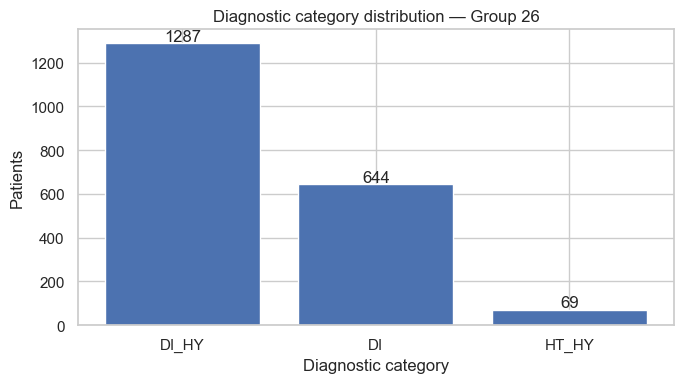

**Observed result.** The data contain **2,000 records**, **35 columns**, **0 missing entries**, and **0 exact duplicate rows**. The largest class (`DI_HY`) represents **64.35%** of patients, whereas the smallest (`HT_HY`) represents only **3.45%**. A classifier predicting only the majority class would reach roughly 64.35% accuracy while failing to recognize the other diagnoses. This motivates macro-F1, balanced accuracy, and per-class recall in addition to accuracy.

In [3]:
class_counts = df['target_class'].value_counts()
class_share = (class_counts / len(df) * 100).round(2)
class_table = pd.DataFrame({'patients': class_counts, 'percentage': class_share})
display(class_table)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_counts.index.astype(str), class_counts.values)
ax.set(title='Diagnostic category distribution — Group 26', xlabel='Diagnostic category', ylabel='Patients')
for i, count in enumerate(class_counts.values):
    ax.text(i, count + 12, str(count), ha='center')
plt.tight_layout(); plt.show()
majority_share = class_share.iloc[0]
display(Markdown(f'''**Observed result.** The data contain **{len(df):,} records**, **{df.shape[1]} columns**, **{df.isna().sum().sum():,} missing entries**, and **{df.duplicated().sum()} exact duplicate rows**. The largest class (`{class_counts.index[0]}`) represents **{majority_share:.2f}%** of patients, whereas the smallest (`{class_counts.index[-1]}`) represents only **{class_share.iloc[-1]:.2f}%**. A classifier predicting only the majority class would reach roughly {majority_share:.2f}% accuracy while failing to recognize the other diagnoses. This motivates macro-F1, balanced accuracy, and per-class recall in addition to accuracy.'''))

## 2. Exploratory Data Analysis (EDA)

**Approach.** The assignment requests three complementary forms of EDA:

1. **Univariate:** histograms for numeric clinical measures, categorical frequencies, and examination of the regression outcome.
2. **Bivariate against the continuous target:** Pearson correlations and scatterplots for numeric features; these measure *linear association*, not causation.
3. **Bivariate against the diagnostic target:** class-conditional distributions and categorical contingency tables; these reveal possible group differences, including minority-class behaviour.

This exploratory analysis uses the provided dataset to describe its overall characteristics. To avoid optimistic model selection, feature rankings used later are recalculated **using training data only**.

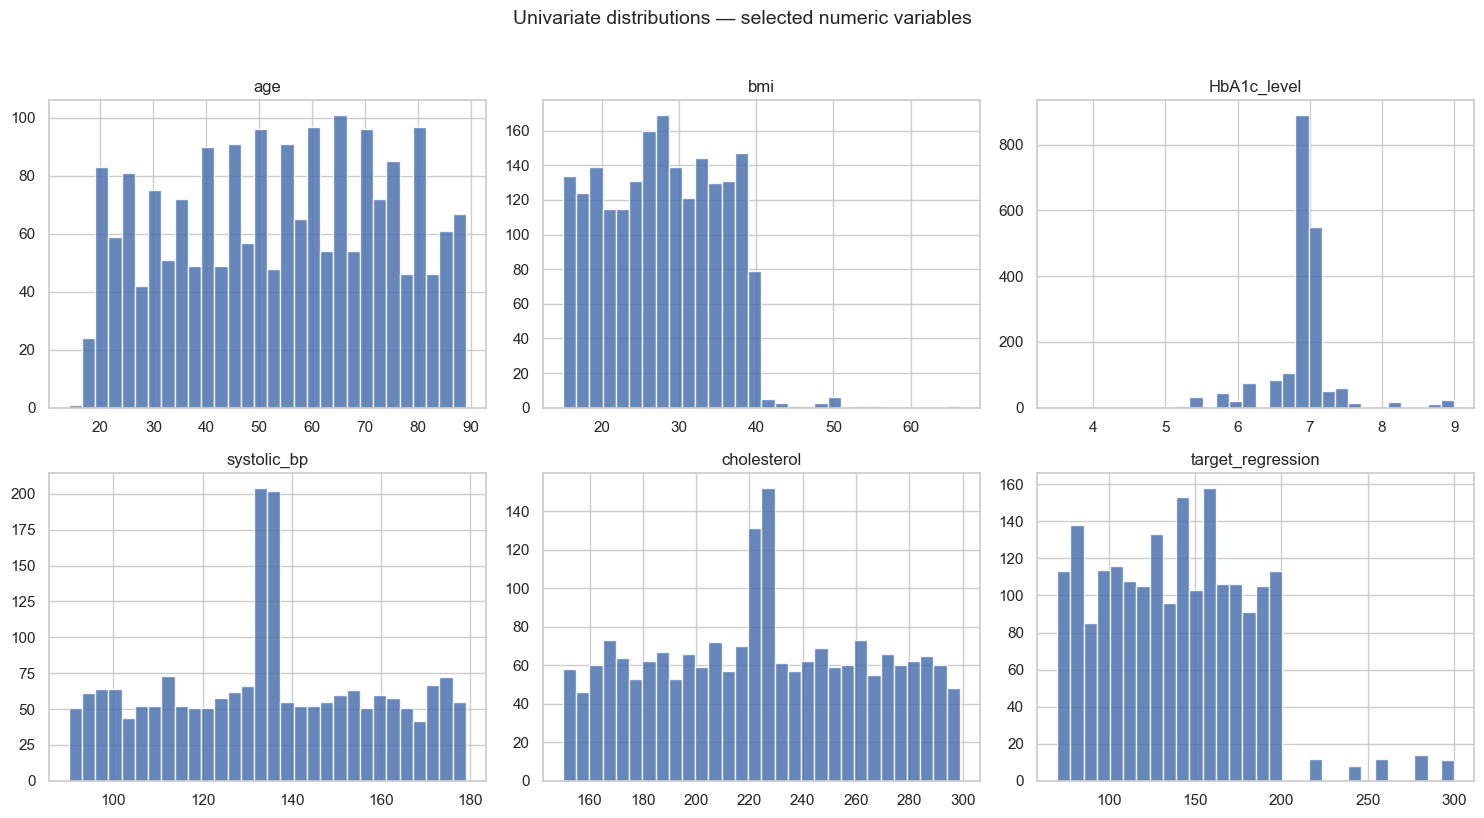

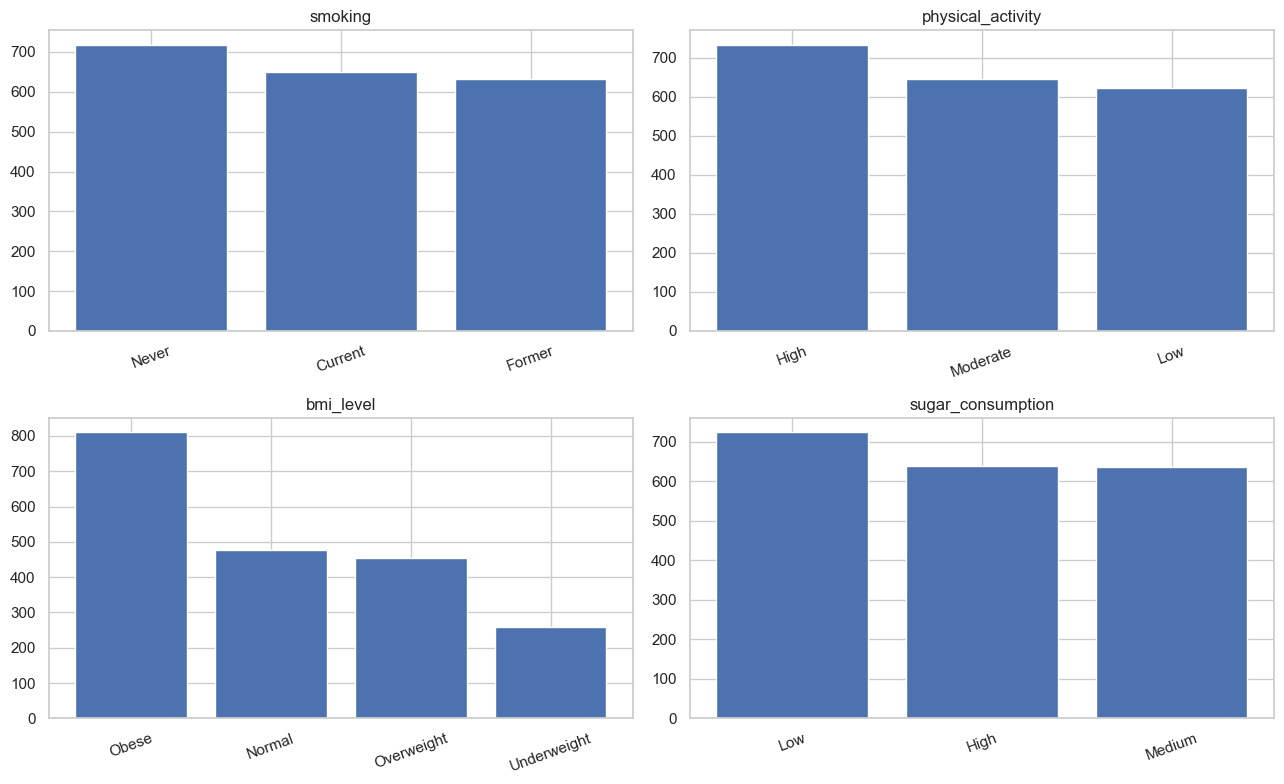

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, var in zip(axs.ravel(), ['age','bmi','HbA1c_level','systolic_bp','cholesterol','target_regression']):
    ax.hist(df[var], bins=30, edgecolor='white', alpha=0.85)
    ax.set_title(var)
plt.suptitle('Univariate distributions — selected numeric variables', y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

cats = ['smoking', 'physical_activity', 'bmi_level', 'sugar_consumption']
fig, axs = plt.subplots(2, 2, figsize=(13, 8))
for ax, var in zip(axs.ravel(), cats):
    counts = df[var].value_counts(); ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(var)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

Top absolute Pearson correlations with regression target:


,Pearson r
bmi,0.0694
HbA1c_level,0.0620
triglycerides,0.0479
heart_rate,-0.0306
homocysteine_level,0.0256
plasma_value,0.0243
hdl,0.0236
crp_level,0.0231
ldl_alternative,0.0216
ldl,-0.0175


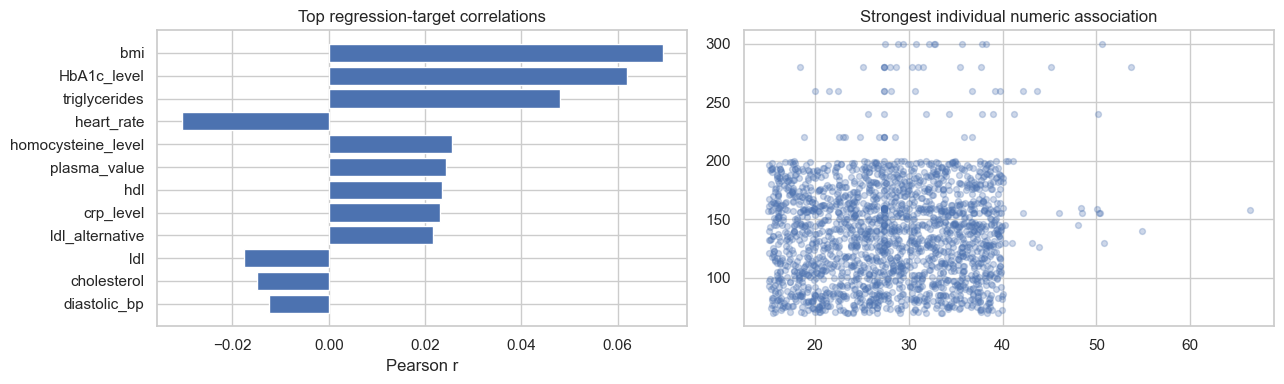

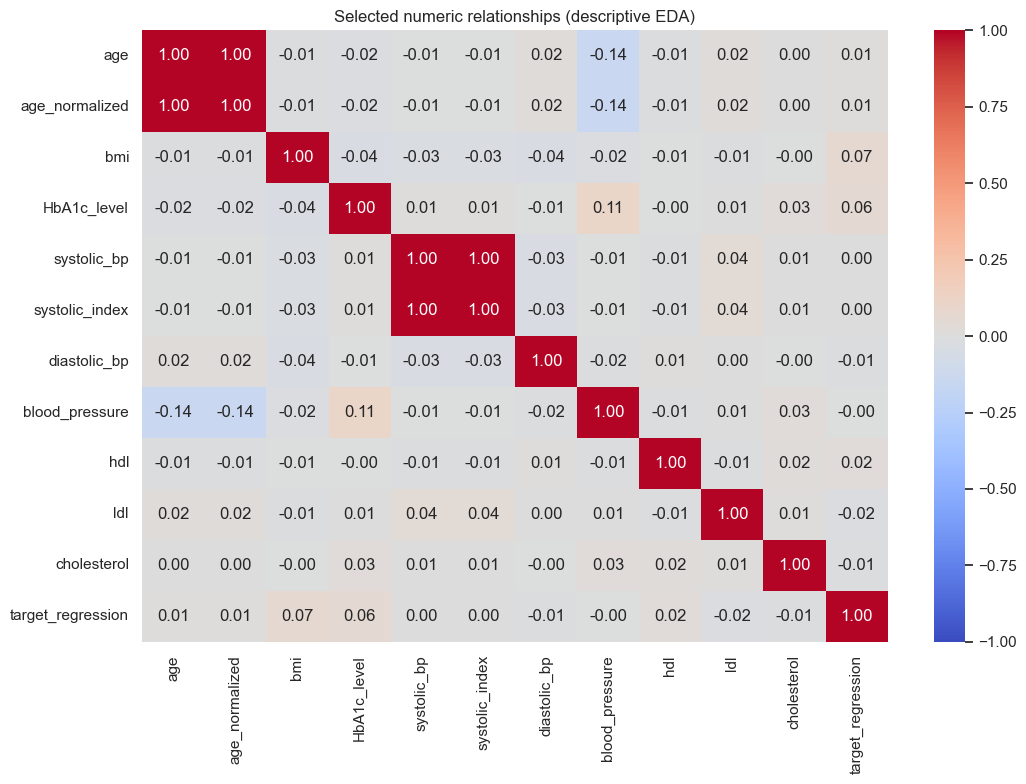

**Observed result.** The strongest measured *individual numeric* correlation with the continuous target is **`bmi` (r = +0.069)**. Its absolute value is 0.069; this provides little evidence of a strong *linear* single-feature predictor. Non-linear relationships may still exist, but the assignment specifically asks us to test linear regression. The histogram also helps establish whether outliers or marked skewness may influence squared-error-based models.

In [5]:
numeric = df.select_dtypes(include='number')
reg_corr = numeric.corr(numeric_only=True)['target_regression'].drop('target_regression').dropna()
rank_corr = reg_corr.reindex(reg_corr.abs().sort_values(ascending=False).index)
print('Top absolute Pearson correlations with regression target:')
display(rank_corr.head(12).rename('Pearson r').to_frame().round(4))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].barh(rank_corr.head(12).index[::-1], rank_corr.head(12).values[::-1])
axs[0].set(xlabel='Pearson r', title='Top regression-target correlations')
axs[1].scatter(df[rank_corr.index[0]], df['target_regression'], alpha=.28, s=18)
axs[1].set(title='Strongest individual numeric association')
plt.tight_layout(); plt.show()

corr_mat = df[['age','age_normalized','bmi','HbA1c_level','systolic_bp',
               'systolic_index','diastolic_bp','blood_pressure','hdl','ldl',
               'cholesterol','target_regression']].corr()
plt.figure(figsize=(11, 8)); sns.heatmap(corr_mat, cmap='coolwarm', vmin=-1, vmax=1,
                                         center=0, annot=True, fmt='.2f')
plt.title('Selected numeric relationships (descriptive EDA)'); plt.tight_layout(); plt.show()
strongest_corr = rank_corr.iloc[0]
display(Markdown(f'''**Observed result.** The strongest measured *individual numeric* correlation with the continuous target is **`{rank_corr.index[0]}` (r = {strongest_corr:+.3f})**. Its absolute value is {abs(strongest_corr):.3f}; this provides little evidence of a strong *linear* single-feature predictor. Non-linear relationships may still exist, but the assignment specifically asks us to test linear regression. The histogram also helps establish whether outliers or marked skewness may influence squared-error-based models.'''))

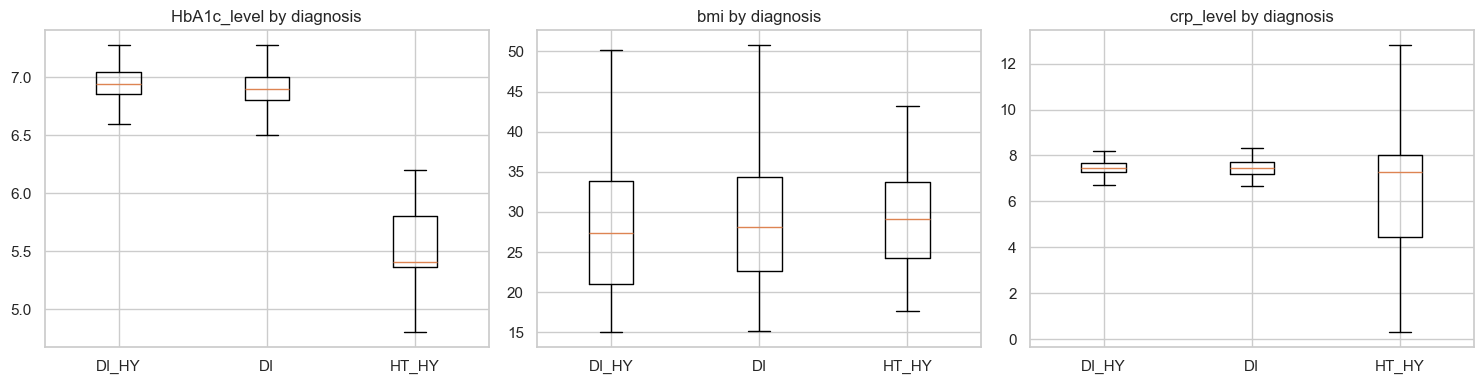

,categorical feature,chi2,p_value,min expected count
7,low_hdl_cholesterol,62.04186,0.00000,12.5925
3,smoking,22.17431,0.00019,21.8385
9,sugar_consumption,14.93564,0.00484,21.9420
10,education_level,13.20212,0.01033,22.7355
2,bmi_level,11.05033,0.08683,8.9355
0,age_level,9.43298,0.15065,5.7615
4,physical_activity,5.41248,0.24753,21.4935
6,stress_level,4.91180,0.29647,22.4250
5,family_history,1.78871,0.40887,34.2930
8,high_ldl_cholesterol,1.68975,0.42961,33.7065


age           bmi       HbA1c_level       systolic_bp         \
               mean    std   mean   std        mean   std        mean    std   
target_class                                                                   
DI            53.64  19.65  28.36  7.56        6.91  0.53      133.70  23.35   
DI_HY         53.54  20.50  27.56  7.30        6.95  0.36      135.12  25.15   
HT_HY         56.67  17.85  29.61  8.24        5.52  0.59      134.39   0.64   

             crp_level        
                  mean   std  
target_class                  
DI                7.39  1.25  
DI_HY             7.35  1.00  
HT_HY             6.76  3.60

**Interpretation.** The boxplots reveal how patient measurements overlap across the three diagnosis categories; separation must be confirmed by predictive validation. Chi-square p-values are exploratory association tests, **not** evidence that a feature causes disease or that it will improve out-of-sample predictions. Small expected contingency counts, multiple comparisons and the small `HT_HY` class limit significance-based conclusions.

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, ['HbA1c_level', 'bmi', 'crp_level']):
    ax.boxplot([df.loc[df.target_class==cl,var] for cl in class_counts.index], tick_labels=class_counts.index, showfliers=False)
    ax.set_title(f'{var} by diagnosis')
plt.tight_layout(); plt.show()

# Categorical bivariate analysis: chi-square tests are descriptive here.
rows = []
for column in df.select_dtypes(exclude='number').columns.drop('target_class'):
    contingency = pd.crosstab(df[column], df['target_class'])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    rows.append({'categorical feature': column, 'chi2': chi2, 'p_value': p_value,
                 'min expected count': expected.min()})
chi_table = pd.DataFrame(rows).sort_values('p_value')
display(chi_table.round(5))

# Complementary numeric comparison by diagnostic class (descriptive, not causal).
num_by_class = df.groupby('target_class')[['age','bmi','HbA1c_level','systolic_bp','crp_level']].agg(['mean','std'])
display(num_by_class.round(2))
display(Markdown('''**Interpretation.** The boxplots reveal how patient measurements overlap across the three diagnosis categories; separation must be confirmed by predictive validation. Chi-square p-values are exploratory association tests, **not** evidence that a feature causes disease or that it will improve out-of-sample predictions. Small expected contingency counts, multiple comparisons and the small `HT_HY` class limit significance-based conclusions.'''))

### 2.1 Data quality, constant and redundant variables

**Approach.** We explicitly inspect constant columns and exact/highly correlated duplicates, because such features add no information or cause multicollinearity. For the fair comparison in later experiments, we retain all **non-redundant** predictors and document exclusions; there is no undisclosed manual deletion on the basis of test results.

In [7]:
predictors = df.drop(columns=['target_class','target_regression'])
constant_cols = predictors.columns[predictors.nunique(dropna=False) <= 1].tolist()
numeric_pred = predictors.select_dtypes(include='number')
abs_corr = numeric_pred.corr().abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
near_identical_pairs = [(c, r, round(float(upper.loc[r,c]), 6))
                        for c in upper for r in upper.index if pd.notna(upper.loc[r,c])
                        and upper.loc[r,c] > 0.99999]
print('Constant predictors:', constant_cols)
print('Near-perfect numeric correlations:', near_identical_pairs)
print('Exact equality systolic_index == systolic_bp:', bool(df['systolic_index'].equals(df['systolic_bp'])))
print('age vs age_normalized Pearson r:', round(df['age'].corr(df['age_normalized']), 8))
# Retain age (years) and systolic_bp (direct measurement).
REMOVED = ['calcium_baseline', 'age_normalized', 'systolic_index']
MODEL_FEATURES = [c for c in predictors.columns if c not in REMOVED]
assert all(x in predictors.columns for x in REMOVED)
print('Original predictors:', predictors.shape[1], '| Model predictors:', len(MODEL_FEATURES))
display(Markdown('''**Decision.** We remove `calcium_baseline` (constant), `systolic_index` (an exact duplicate of `systolic_bp`) and `age_normalized` (an almost exact linear rescaling of `age`). These three exclusions are based on structural redundancy, not validation performance. All remaining predictors are retained for the full-feature classification baseline. We preserve real-world variables `age` and `systolic_bp` to aid interpretation.'''))

Constant predictors: ['calcium_baseline']
Near-perfect numeric correlations: [('age_normalized', 'age', 1.0), ('systolic_index', 'systolic_bp', 1.0)]
Exact equality systolic_index == systolic_bp: True
age vs age_normalized Pearson r: 1.0
Original predictors: 33 | Model predictors: 30


**Decision.** We remove `calcium_baseline` (constant), `systolic_index` (an exact duplicate of `systolic_bp`) and `age_normalized` (an almost exact linear rescaling of `age`). These three exclusions are based on structural redundancy, not validation performance. All remaining predictors are retained for the full-feature classification baseline. We preserve real-world variables `age` and `systolic_bp` to aid interpretation.

## 3. Experimental protocol and leakage prevention

**Approach.** We reserve **20%** of patients as a common final holdout set and use the other **80%** for selecting models and comparing resampling strategies. Stratifying by diagnostic class ensures the small class is represented in both sets; using the same patients for regression and classification makes the experiments reproducible. The holdout is not used for selecting features, hyperparameters or the preferred algorithm. Training-only cross-validation employs 5 or 10 folds as indicated below.

Numerical predictors are median-imputed and standardized; categorical predictors are mode-imputed and one-hot encoded. Although the supplied CSV has no missing values, the imputation makes the workflow robust. Fitting these transformations inside each CV fold prevents information from the validation fold from influencing preprocessing.

In [8]:
indices = np.arange(len(df))
train_ids, test_ids = train_test_split(indices, test_size=.20, stratify=df['target_class'], random_state=SEED)
X_train = df.loc[train_ids, MODEL_FEATURES].copy()
X_test = df.loc[test_ids, MODEL_FEATURES].copy()
yreg_train = df.loc[train_ids, 'target_regression'].copy()
yreg_test = df.loc[test_ids, 'target_regression'].copy()
ycls_train = df.loc[train_ids, 'target_class'].copy()
ycls_test = df.loc[test_ids, 'target_class'].copy()
assert not set(train_ids).intersection(set(test_ids))
print('Train:', len(train_ids), '| Holdout:', len(test_ids), '\nTraining diagnosis frequencies:')
display(ycls_train.value_counts().to_frame('patients'))
print('Holdout diagnosis frequencies:')
display(ycls_test.value_counts().to_frame('patients'))

def preprocessor(feature_frame):
    numeric_cols = feature_frame.select_dtypes(include='number').columns.tolist()
    categorical_cols = feature_frame.select_dtypes(exclude='number').columns.tolist()
    steps = []
    if numeric_cols:
        steps.append(('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())]), numeric_cols))
    if categorical_cols:
        steps.append(('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
        ]), categorical_cols))
    return ColumnTransformer(steps, remainder='drop', sparse_threshold=0)

def full_pipeline(features, estimator):
    return Pipeline([('prepare', preprocessor(features)), ('model', estimator)])

reg_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cls_cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cls_cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
reg_scoring = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}
cls_scoring = {'accuracy': 'accuracy','balanced_accuracy': 'balanced_accuracy','macro_f1': 'f1_macro'}

Train: 1600 | Holdout: 400 
Training diagnosis frequencies:


,patients
target_class,
DI_HY,1030
DI,515
HT_HY,55


Holdout diagnosis frequencies:


,patients
target_class,
DI_HY,257
DI,129
HT_HY,14


## 4. Regression: simple linear model (assignment §3)

**Research question.** Can a single patient characteristic predict `target_regression`? **Approach.** We fit a separate ordinary least-squares model for every available numeric predictor, comparing **training-only 5-fold CV RMSE**. This avoids arbitrarily selecting the feature that looks best in the full dataset. Our comparator is a dummy regressor that always predicts the training mean. We will assess the best simple model once on the untouched holdout set.

For one predictor, the fitted relationship is \(\hat y = \beta_0 + \beta_1 x\). Lower RMSE/MAE and higher R² indicate better generalisation. R² can be negative on holdout data, meaning the model performs worse than a constant mean-based reference on that set.

,feature,CV RMSE,CV MAE,CV R2,CV RMSE sd
0,bmi,43.0517,34.9817,-0.0009,2.5482
1,HbA1c_level,43.0755,34.9475,-0.0021,2.4860
2,crp_level,43.1149,34.9633,-0.0037,2.6105
3,hdl,43.1162,34.9391,-0.0037,2.6205
4,heart_rate,43.1195,34.9872,-0.0039,2.6032
5,triglycerides,43.1196,34.9967,-0.0041,2.5208
6,sleep_hours,43.1256,34.9742,-0.0042,2.6126
7,homocysteine_level,43.1261,34.9515,-0.0042,2.6136
8,alcohol_intake,43.1274,34.9656,-0.0043,2.6146
9,salt_intake,43.1288,34.9816,-0.0043,2.6140


Selected simple predictor (training CV): bmi


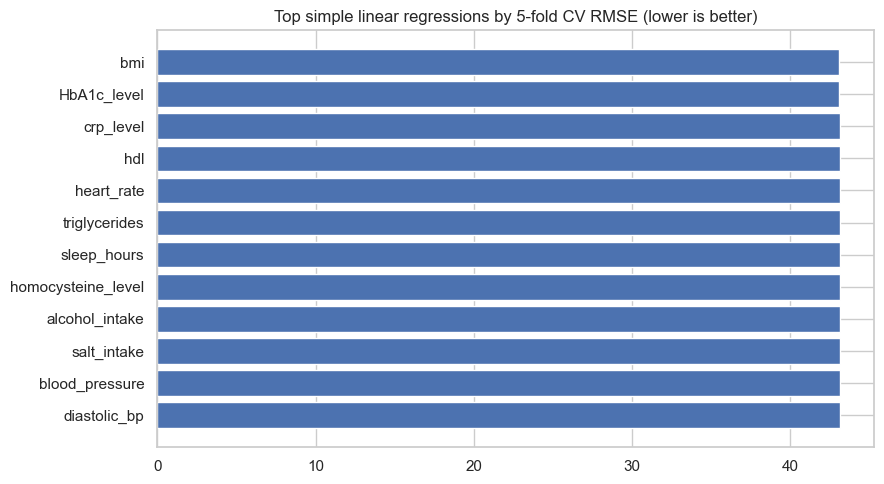

In [9]:
numeric_candidates = X_train.select_dtypes(include='number').columns.tolist()
simple_rows = []
for var in numeric_candidates:
    model = full_pipeline(X_train[[var]], LinearRegression())
    scores = cross_validate(model, X_train[[var]], yreg_train, cv=reg_cv,
                            scoring=reg_scoring, n_jobs=1)
    simple_rows.append({'feature': var, 'CV RMSE': -scores['test_rmse'].mean(),
                        'CV MAE': -scores['test_mae'].mean(),
                        'CV R2': scores['test_r2'].mean(),
                        'CV RMSE sd': scores['test_rmse'].std(ddof=1)})
simple_results = pd.DataFrame(simple_rows).sort_values('CV RMSE').reset_index(drop=True)
best_single = simple_results.loc[0, 'feature']
display(simple_results.round(4))
print('Selected simple predictor (training CV):', best_single)
fig, ax = plt.subplots(figsize=(9, 5))
top = simple_results.head(12).iloc[::-1]; ax.barh(top['feature'], top['CV RMSE'])
ax.set(title='Top simple linear regressions by 5-fold CV RMSE (lower is better)')
plt.tight_layout(); plt.show()

Fitted unscaled equation: target_regression = 127.585 + (+0.3926) × bmi


,model,MAE,RMSE,R2
0,Simple LR: bmi,32.1912,38.8853,0.0032


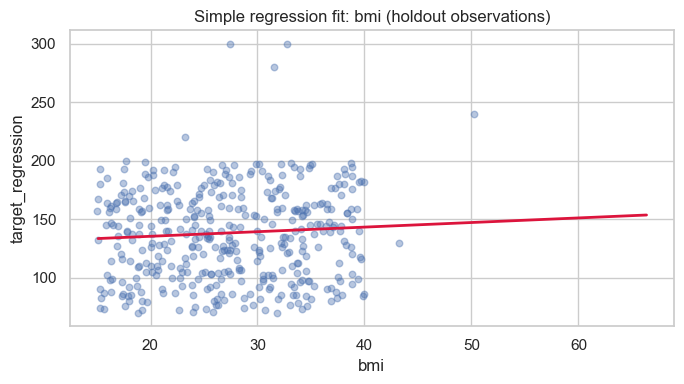

**Observed result.** Training CV selected **`bmi`**. On the untouched holdout, simple regression achieved **R² = 0.003, MAE = 32.19, RMSE = 38.89**. The R² measures the fraction of holdout variation explained relative to a constant baseline. A visually noticeable trend does not necessarily translate into useful patient-level predictions.

In [10]:
simple_best = full_pipeline(X_train[[best_single]], LinearRegression())
simple_best.fit(X_train[[best_single]], yreg_train)
simple_pred = simple_best.predict(X_test[[best_single]])
simple_score = {'model': f'Simple LR: {best_single}',
                'MAE': mean_absolute_error(yreg_test, simple_pred),
                'RMSE': np.sqrt(mean_squared_error(yreg_test, simple_pred)),
                'R2': r2_score(yreg_test, simple_pred)}
# Interpret coefficients on the original feature scale by fitting OLS without standardization.
raw_single = LinearRegression().fit(X_train[[best_single]], yreg_train)
print(f'Fitted unscaled equation: target_regression = {raw_single.intercept_:.3f} '
      f'+ ({raw_single.coef_[0]:+.4f}) × {best_single}')
display(pd.DataFrame([simple_score]).round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_test[best_single], yreg_test, s=22, alpha=.4)
x_grid = np.linspace(X_train[best_single].min(), X_train[best_single].max(), 200)
ax.plot(x_grid, raw_single.predict(pd.DataFrame({best_single:x_grid})), color='crimson', lw=2)
ax.set(title=f'Simple regression fit: {best_single} (holdout observations)',
       xlabel=best_single, ylabel='target_regression')
plt.tight_layout(); plt.show()
display(Markdown(f'''**Observed result.** Training CV selected **`{best_single}`**. On the untouched holdout, simple regression achieved **R² = {simple_score['R2']:.3f}, MAE = {simple_score['MAE']:.2f}, RMSE = {simple_score['RMSE']:.2f}**. {'The negative R² shows worse performance than predicting the holdout mean.' if simple_score['R2'] < 0 else 'The R² measures the fraction of holdout variation explained relative to a constant baseline.'} A visually noticeable trend does not necessarily translate into useful patient-level predictions.'''))

## 5. Regression: multiple linear model and comparison (assignment §3)

**Research question.** Does adding several clinical predictors improve on the best one-feature model? **Approach.** We compare interpretable feature combinations (top 2, 4 and 8 numeric predictors **re-ranked within each validation-training fold**), a domain-motivated cardiometabolic subset, and the full set of non-redundant predictors (including encoded categories). We select the multiple model by lowest **training CV RMSE**. The common held-out test partition is evaluated **once** for the chosen simple model, chosen multiple model, and a training-mean baseline. We do not claim that adding variables will necessarily help: weak signal and collinearity can worsen predictive error.

To prevent information leakage in 5-fold model comparison, each top-k feature ranking is recalculated inside that fold using only its training portion. Once a feature-count strategy is chosen by CV, we apply that strategy to all 1,600 training patients before the final holdout evaluation.

In [11]:
from sklearn.base import TransformerMixin, BaseEstimator
class TopKNumericCorrelation(TransformerMixin, BaseEstimator):
    """Select k numeric features using only data passed to fit()."""
    def __init__(self, k=2):
        self.k = k
    def fit(self, X, y):
        correlations = X.select_dtypes(include='number').corrwith(pd.Series(np.asarray(y), index=X.index)).abs()
        self.features_ = correlations.dropna().nlargest(self.k).index.tolist()
        return self
    def transform(self, X):
        return X[self.features_]

train_corr = X_train.select_dtypes(include='number').corrwith(yreg_train).abs().dropna().sort_values(ascending=False)
ranked = train_corr.index.tolist()
clinical_subset = [c for c in ['age','bmi','HbA1c_level','systolic_bp',
                                 'cholesterol','triglycerides','hdl','ldl','crp_level'] if c in X_train]
feature_groups = {'Top 2 numeric': ranked[:2],
                  'Top 4 numeric': ranked[:4],
                  'Top 8 numeric': ranked[:8],
                  'Clinical indicators': clinical_subset,
                  'All cleaned features': MODEL_FEATURES}
multi_rows = []
for label, cols in feature_groups.items():
    if label.startswith('Top '):
        k = int(label.split()[1])
        model = Pipeline([('select', TopKNumericCorrelation(k=k)),
                          ('imputer',SimpleImputer(strategy='median')),
                          ('scaler',StandardScaler()),('model',LinearRegression())])
        fold_X = X_train
    else:
        model = full_pipeline(X_train[cols], LinearRegression())
        fold_X = X_train[cols]
    cv = cross_validate(model, fold_X, yreg_train, cv=reg_cv,
                        scoring=reg_scoring, n_jobs=1)
    multi_rows.append({'group': label, 'features': len(cols),
                       'CV RMSE': -cv['test_rmse'].mean(),
                       'CV MAE': -cv['test_mae'].mean(),
                       'CV R2': cv['test_r2'].mean(),
                       'CV RMSE sd': cv['test_rmse'].std(ddof=1)})
multi_results = pd.DataFrame(multi_rows).sort_values('CV RMSE').reset_index(drop=True)
best_multiple = multi_results.loc[0, 'group']
print('Training-only feature correlation ranking:')
display(train_corr.head(12).to_frame('|r|').round(4))
display(multi_results.round(4))
print('Chosen multiple model:', best_multiple, '| Features:', feature_groups[best_multiple])

Training-only feature correlation ranking:


,|r|
bmi,0.0682
HbA1c_level,0.0681
triglycerides,0.0491
crp_level,0.0329
heart_rate,0.0288
hdl,0.0279
plasma_value,0.0223
homocysteine_level,0.0220
age,0.0144
ldl_alternative,0.0102


,group,features,CV RMSE,CV MAE,CV R2,CV RMSE sd
0,Top 2 numeric,2,43.0421,35.0011,-0.0007,2.4615
1,Top 4 numeric,4,43.1368,35.0907,-0.0053,2.3990
2,Clinical indicators,9,43.1421,35.0630,-0.0057,2.3231
3,Top 8 numeric,8,43.1785,35.1426,-0.0076,2.2519
4,All cleaned features,30,43.3118,35.3412,-0.0142,2.1448


Chosen multiple model: Top 2 numeric | Features: ['bmi', 'HbA1c_level']


,model,MAE,RMSE,R2
0,Training-mean baseline,32.2331,38.9979,-0.0026
1,Simple LR: bmi,32.1912,38.8853,0.0032
2,Multiple LR: Top 2 numeric,32.1896,38.8743,0.0037


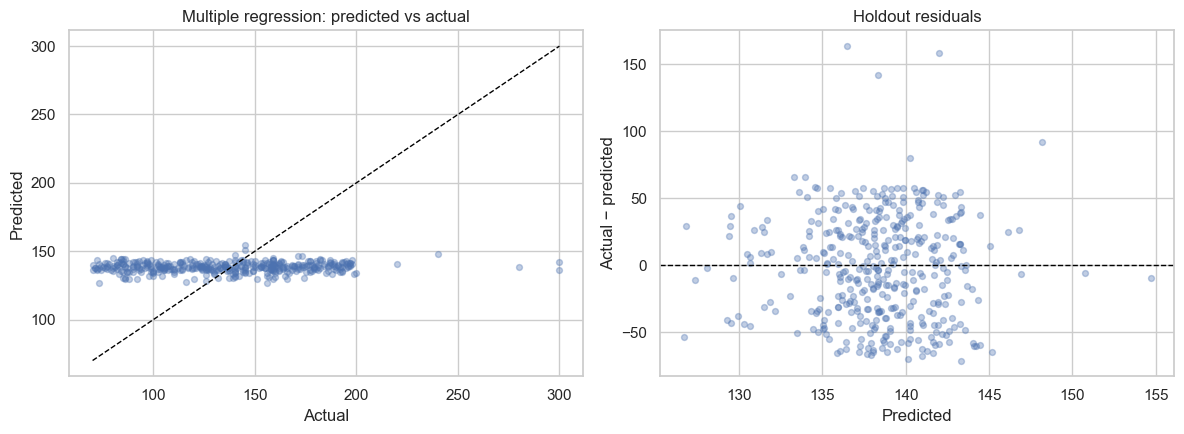

**Observed result.** The multiple model selected by 5-fold training CV was **Top 2 numeric**, comprising **2 original predictors**. Its holdout scores were **R² = 0.004, MAE = 32.19, RMSE = 38.87**; the simple model's RMSE was **38.89**, and the training-mean baseline's RMSE was **39.00**. The smallest observed holdout RMSE belongs to **Multiple LR: Top 2 numeric**. We compare the outcomes transparently, but **do not re-select or retune models on these test scores**. Weak positive or negative R² is evidence of limited linear predictability in this dataset, not a programming error.

In [12]:
selected_multi_cols = feature_groups[best_multiple]
multiple_best = full_pipeline(X_train[selected_multi_cols], LinearRegression())
multiple_best.fit(X_train[selected_multi_cols], yreg_train)
multi_pred = multiple_best.predict(X_test[selected_multi_cols])
dummy_reg = DummyRegressor(strategy='mean').fit(X_train, yreg_train)
dummy_pred = dummy_reg.predict(X_test)
reg_compare = pd.DataFrame([
    {'model':'Training-mean baseline','MAE': mean_absolute_error(yreg_test,dummy_pred),
     'RMSE':np.sqrt(mean_squared_error(yreg_test,dummy_pred)),'R2':r2_score(yreg_test,dummy_pred)},
    simple_score,
    {'model':f'Multiple LR: {best_multiple}', 'MAE':mean_absolute_error(yreg_test,multi_pred),
     'RMSE':np.sqrt(mean_squared_error(yreg_test,multi_pred)),'R2':r2_score(yreg_test,multi_pred)}
])
display(reg_compare.round(4))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].scatter(yreg_test, multi_pred, alpha=.35, s=18)
lo=min(yreg_test.min(),multi_pred.min()); hi=max(yreg_test.max(),multi_pred.max())
axs[0].plot([lo,hi],[lo,hi],'--',color='black',lw=1)
axs[0].set(title='Multiple regression: predicted vs actual', xlabel='Actual', ylabel='Predicted')
axs[1].scatter(multi_pred, yreg_test-multi_pred, alpha=.35, s=18)
axs[1].axhline(0,ls='--',color='black',lw=1)
axs[1].set(title='Holdout residuals',xlabel='Predicted',ylabel='Actual − predicted')
plt.tight_layout();plt.show()
winner_reg = reg_compare.sort_values('RMSE').iloc[0]
display(Markdown(f'''**Observed result.** The multiple model selected by 5-fold training CV was **{best_multiple}**, comprising **{len(selected_multi_cols)} original predictors**. Its holdout scores were **R² = {reg_compare.iloc[2]['R2']:.3f}, MAE = {reg_compare.iloc[2]['MAE']:.2f}, RMSE = {reg_compare.iloc[2]['RMSE']:.2f}**; the simple model's RMSE was **{reg_compare.iloc[1]['RMSE']:.2f}**, and the training-mean baseline's RMSE was **{reg_compare.iloc[0]['RMSE']:.2f}**. The smallest observed holdout RMSE belongs to **{winner_reg['model']}**. We compare the outcomes transparently, but **do not re-select or retune models on these test scores**. Weak positive or negative R² is evidence of limited linear predictability in this dataset, not a programming error.'''))

## 6. Classification: Logistic Regression versus LDA (assignment §4)

**Research question.** Can the patient profile predict which of the three diagnostic categories (`DI`, `DI_HY`, `HT_HY`) a patient belongs to? **Approach.** We compare:

- **Multinomial Logistic Regression:** discriminative linear decision boundaries; balanced class weights help account for the rare class.
- **Linear Discriminant Analysis (LDA):** class-conditional Gaussian model with pooled covariance; shrinkage stabilizes estimation in the presence of correlated encoded predictors. LDA uses empirical class priors by default; this differs from the explicit weighting of Logistic Regression and should be considered when discussing minority recall.
- **Most-frequent dummy classifier:** a transparent reference.

Our primary selection metric is **macro-F1**, which gives equal importance to each diagnostic class. We also examine balanced accuracy, accuracy, class-specific precision/recall, and confusion matrices. Class weights are used only for Logistic Regression; changing the class priors in LDA would constitute a separate design choice.

In [13]:
CLASSIFIERS = {
    'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced', solver='lbfgs'),
    'LDA (shrinkage)': LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')
}
base_classifier = DummyClassifier(strategy='most_frequent')
# Model comparison on training data only, using the same 5-fold splits.
cv_rows=[]
for label, estimator in [('Majority baseline',base_classifier), *CLASSIFIERS.items()]:
    candidate = full_pipeline(X_train, estimator)
    results = cross_validate(candidate, X_train, ycls_train, cv=cls_cv5,
                             scoring=cls_scoring, n_jobs=1)
    cv_rows.append({'model':label,
                    'CV macro-F1':results['test_macro_f1'].mean(),
                    'CV macro-F1 sd':results['test_macro_f1'].std(ddof=1),
                    'CV balanced acc.':results['test_balanced_accuracy'].mean(),
                    'CV accuracy':results['test_accuracy'].mean()})
class_cv_table=pd.DataFrame(cv_rows).sort_values('CV macro-F1',ascending=False)
display(class_cv_table.round(4))
selected_classifier_name = (class_cv_table[class_cv_table['model'].isin(CLASSIFIERS)]
                            .sort_values('CV macro-F1').iloc[-1]['model'])
print('Selected (5-fold training macro-F1):',selected_classifier_name)

,model,CV macro-F1,CV macro-F1 sd,CV balanced acc.,CV accuracy
2,LDA (shrinkage),0.5860,0.0292,0.6193,0.6612
1,Logistic Regression,0.5768,0.0153,0.6382,0.5544
0,Majority baseline,0.2611,0.0000,0.3333,0.6438


Selected (5-fold training macro-F1): LDA (shrinkage)


### 6.1 Holdout evaluation and error diagnosis

**Approach.** After comparing the algorithms using training-only CV, we fit both methods on all training patients and report their 400-patient holdout performance. We inspect the three-class confusion matrices directly: each **row represents a true class**, and each **column represents the predicted class** (scikit-learn convention). The minor class deserves special attention, because high global accuracy can coexist with many missed minority cases.

,model,accuracy,balanced accuracy,macro-F1
1,Logistic Regression,0.5150,0.5406,0.5176
2,LDA (shrinkage),0.6450,0.5051,0.5130
0,Majority baseline,0.6425,0.3333,0.2608


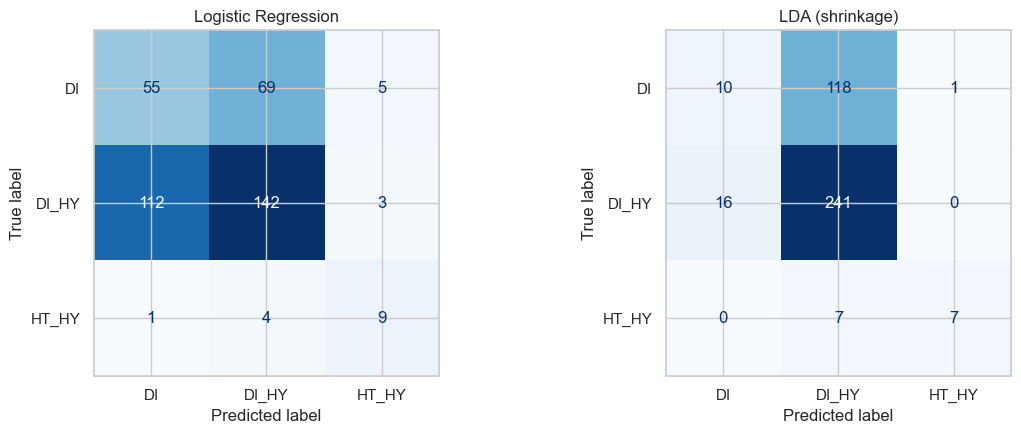


=== Logistic Regression ===
              precision    recall  f1-score   support

          DI      0.327     0.426     0.370       129
       DI_HY      0.660     0.553     0.602       257
       HT_HY      0.529     0.643     0.581        14

    accuracy                          0.515       400
   macro avg      0.506     0.541     0.518       400
weighted avg      0.548     0.515     0.526       400


=== LDA (shrinkage) ===
              precision    recall  f1-score   support

          DI      0.385     0.078     0.129       129
       DI_HY      0.658     0.938     0.774       257
       HT_HY      0.875     0.500     0.636        14

    accuracy                          0.645       400
   macro avg      0.639     0.505     0.513       400
weighted avg      0.578     0.645     0.561       400



**Observed result.** **LDA (shrinkage)** was selected using training CV macro-F1. Its independent holdout results were **accuracy 0.645, balanced accuracy 0.505, macro-F1 0.513**. On the rare `HT_HY` class (only **14** holdout patients), Logistic Regression recalled **64.3%**, and LDA recalled **50.0%**. The full classification report clarifies which classes each algorithm gets right and wrong; accuracy alone would conceal this difference.

In [14]:
holdout_models = {'Majority baseline':full_pipeline(X_train,base_classifier),
                  **{name:full_pipeline(X_train,est) for name,est in CLASSIFIERS.items()}}
cls_holdout_rows=[]
cls_predictions={}
for label, model in holdout_models.items():
    model.fit(X_train, ycls_train)
    pred = model.predict(X_test)
    cls_predictions[label] = pred
    cls_holdout_rows.append({'model': label, 'accuracy':accuracy_score(ycls_test,pred),
                             'balanced accuracy':balanced_accuracy_score(ycls_test,pred),
                             'macro-F1':f1_score(ycls_test,pred,average='macro',zero_division=0)})
cls_holdout_table=pd.DataFrame(cls_holdout_rows).sort_values('macro-F1',ascending=False)
display(cls_holdout_table.round(4))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, label in zip(axs, CLASSIFIERS):
    ConfusionMatrixDisplay.from_predictions(ycls_test, cls_predictions[label],
                                            labels=sorted(class_counts.index),
                                            ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(label)
plt.tight_layout();plt.show()
for label in CLASSIFIERS:
    print('\n===',label,'===')
    print(classification_report(ycls_test, cls_predictions[label],zero_division=0,digits=3))
minority = class_counts.index[-1]
minority_recall = {name: (np.sum((ycls_test.to_numpy()==minority)&(pred==minority)) /
                          np.sum(ycls_test.to_numpy()==minority))
                   for name,pred in cls_predictions.items()}
cv_selected_row = cls_holdout_table.set_index('model').loc[selected_classifier_name]
display(Markdown(f'''**Observed result.** **{selected_classifier_name}** was selected using training CV macro-F1. Its independent holdout results were **accuracy {cv_selected_row['accuracy']:.3f}, balanced accuracy {cv_selected_row['balanced accuracy']:.3f}, macro-F1 {cv_selected_row['macro-F1']:.3f}**. On the rare `{minority}` class (only **{int((ycls_test==minority).sum())}** holdout patients), Logistic Regression recalled **{minority_recall['Logistic Regression']:.1%}**, and LDA recalled **{minority_recall['LDA (shrinkage)']:.1%}**. The full classification report clarifies which classes each algorithm gets right and wrong; accuracy alone would conceal this difference.'''))

## 7. Resampling: variability and stability (assignment §4)

**Research question.** How sensitive are our model assessments to sampling methodology? **Approach.** Apply the same two classifiers and metric (macro-F1) to a repeated stratified holdout study, 5-fold CV, 10-fold CV, exact LOOCV, and bootstrap out-of-bag assessment.

**Important distinction:** 5-fold/10-fold CV provides fold-level score variation, repeated holdout gives variation across independent random partitions (not independent scores), and bootstrap OOB evaluates out-of-bag observations that change across replications. LOOCV has one observation per validation fold, so a *single-fold macro-F1 is not statistically meaningful*. We aggregate all LOOCV out-of-fold predictions before calculating macro-F1, and do **not** report a misleading standard deviation of 1-observation scores. These methods estimate related but not identical quantities, so the numerical variances should be interpreted carefully.

In [15]:
resample_rows=[]
resample_samples={}

def add_sample_results(name, method, values):
    values=np.array(values,dtype=float)
    resample_samples[(name,method)]=values
    resample_rows.append({'model':name,'method':method, 'repeats':len(values),
                          'mean macro-F1':values.mean(),
                          'sd macro-F1':values.std(ddof=1) if len(values)>1 else np.nan,
                          'variance':values.var(ddof=1) if len(values)>1 else np.nan})

for name,est in CLASSIFIERS.items():
    pipeline = full_pipeline(X_train,est)
    # Consistent 5-fold and 10-fold CV, on the held-out-free training partition.
    for k,cv in [(5,cls_cv5),(10,cls_cv10)]:
        scores = cross_validate(pipeline,X_train,ycls_train,cv=cv,
                                scoring='f1_macro',n_jobs=1)['test_score']
        add_sample_results(name,f'{k}-fold CV',scores)
    # Repeat stratified holdout within the training partition; fixed 25% validation size.
    shuffle = StratifiedShuffleSplit(n_splits=15,test_size=.25,random_state=SEED)
    repeated=[]
    for tr,va in shuffle.split(X_train,ycls_train):
        model=clone(pipeline)
        model.fit(X_train.iloc[tr],ycls_train.iloc[tr])
        predictions=model.predict(X_train.iloc[va])
        repeated.append(f1_score(ycls_train.iloc[va],predictions,average='macro',zero_division=0))
    add_sample_results(name,'Repeated holdout (15)',repeated)
print('Cross-validation and repeated-holdout computations complete.')

Cross-validation and repeated-holdout computations complete.


### 7.1 Leave-One-Out Cross-Validation (LOOCV)

**Approach.** We conduct **exact LOOCV on a stratified 400-patient subset of the training partition**, fitting the full preprocessing-and-classifier pipeline 400 times for each method. Every patient is predicted once by a model trained on all other training patients. We pool those predictions to calculate macro-F1 and balanced accuracy; per-fold F1 scores are not used. We explicitly retain the final 400-person holdout untouched. The subset is selected deterministically by stratified sampling from the training partition to keep computation feasible. This is genuine LOOCV on those 400 patients, but it estimates performance for a smaller training size and is not directly comparable with full-training CV estimates.

In [16]:
# Stratified, reproducible sample: exact LOOCV on 400 training patients.
loo_subset, _unused = train_test_split(np.arange(len(X_train)), train_size=400,
                                      stratify=ycls_train, random_state=SEED)
X_loo = X_train.iloc[loo_subset]
y_loo = ycls_train.iloc[loo_subset]
loo = LeaveOneOut()
loocv_results=[]
for name, est in CLASSIFIERS.items():
    print('Running exact LOOCV on 400 training patients:',name,flush=True)
    predicted = cross_val_predict(full_pipeline(X_loo,est), X_loo, y_loo,
                                  cv=loo, n_jobs=1, method='predict')
    loocv_results.append({'model':name,
                          'LOOCV pooled macro-F1':f1_score(y_loo,predicted,average='macro',zero_division=0),
                          'LOOCV pooled balanced accuracy':balanced_accuracy_score(y_loo,predicted),
                          'LOOCV pooled accuracy':accuracy_score(y_loo,predicted)})
loocv_table = pd.DataFrame(loocv_results)
display(loocv_table.round(4))
print('LOOCV sample: 400 (stratified subset of training), pooled predictions.')

Running exact LOOCV on 400 training patients: Logistic Regression
Running exact LOOCV on 400 training patients: LDA (shrinkage)


,model,LOOCV pooled macro-F1,LOOCV pooled balanced accuracy,LOOCV pooled accuracy
0,Logistic Regression,0.6275,0.6327,0.5475
1,LDA (shrinkage),0.5544,0.5435,0.6075


LOOCV sample: 400 (stratified subset of training), pooled predictions.


### 7.2 Bootstrap with out-of-bag (OOB) assessment

**Approach.** For each of 60 bootstrap replicates, sample 1,600 training patient indices **with replacement**. Fit the model on the resampled patients, evaluate on the **out-of-bag** patients never included in that replicate, and record macro-F1. Bootstrap samples may contain fewer than 1,600 unique patients. We verify that every fitted replicate includes all three target classes and that each OOB set contains all three for interpretable macro-F1; skipped draws would be explicitly counted. Although OOB testing reuses observations across repeats, it provides a useful measure of evaluation instability.

In [17]:
BOOTSTRAP_REPEATS=60
bootstrap_sizes={}
for name, est in CLASSIFIERS.items():
    scores=[]; sizes=[]; skipped=0
    boot_rng=np.random.default_rng(SEED+100)
    pipe=full_pipeline(X_train,est)
    for iteration in range(BOOTSTRAP_REPEATS):
        boot_indices=boot_rng.integers(0,len(X_train),size=len(X_train))
        unseen=np.setdiff1d(np.arange(len(X_train)),np.unique(boot_indices))
        if (ycls_train.iloc[boot_indices].nunique()<3 or
                ycls_train.iloc[unseen].nunique()<3):
            skipped+=1
            continue
        model=clone(pipe)
        model.fit(X_train.iloc[boot_indices],ycls_train.iloc[boot_indices])
        output=model.predict(X_train.iloc[unseen])
        scores.append(f1_score(ycls_train.iloc[unseen],output,average='macro',zero_division=0))
        sizes.append(len(unseen))
    add_sample_results(name,'Bootstrap OOB (60)',scores)
    bootstrap_sizes[name]=(np.mean(sizes),skipped)
    print(f'{name}: {len(scores)} valid draws, mean OOB size {np.mean(sizes):.1f}, skipped {skipped}')

Logistic Regression: 60 valid draws, mean OOB size 588.4, skipped 0
LDA (shrinkage): 60 valid draws, mean OOB size 588.4, skipped 0


,model,method,repeats,mean macro-F1,sd macro-F1,variance
0,LDA (shrinkage),10-fold CV,10,0.58440,0.03897,0.00152
1,LDA (shrinkage),5-fold CV,5,0.58598,0.02921,0.00085
2,LDA (shrinkage),Bootstrap OOB (60),60,0.58245,0.02338,0.00055
3,LDA (shrinkage),Repeated holdout (15),15,0.58747,0.01855,0.00034
4,Logistic Regression,10-fold CV,10,0.57597,0.05878,0.00346
5,Logistic Regression,5-fold CV,5,0.57685,0.01530,0.00023
6,Logistic Regression,Bootstrap OOB (60),60,0.57404,0.02813,0.00079
7,Logistic Regression,Repeated holdout (15),15,0.57270,0.02454,0.00060


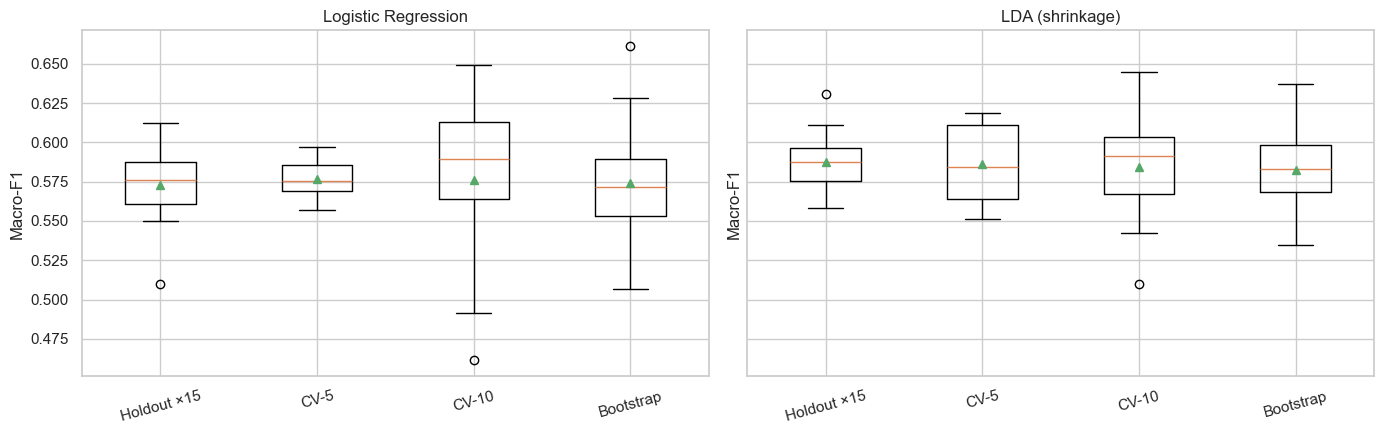

**Logistic Regression:** CV-5 mean macro-F1 **0.577** (SD **0.015**); CV-10 **0.576** (SD **0.059**); repeated holdout **0.573** (SD **0.025**); bootstrap OOB **0.574** (SD **0.028**); pooled LOOCV macro-F1 **0.627**. The smallest observed score SD among the repeated/fold-based procedures is **5-fold CV**, but comparisons of SD are **descriptive** because the procedures have different test-set sizes, training-set sizes and dependencies.

**LDA (shrinkage):** CV-5 mean macro-F1 **0.586** (SD **0.029**); CV-10 **0.584** (SD **0.039**); repeated holdout **0.587** (SD **0.019**); bootstrap OOB **0.582** (SD **0.023**); pooled LOOCV macro-F1 **0.554**. The smallest observed score SD among the repeated/fold-based procedures is **Repeated holdout (15)**, but comparisons of SD are **descriptive** because the procedures have different test-set sizes, training-set sizes and dependencies.

In [18]:
variance_summary=pd.DataFrame(resample_rows).sort_values(['model','method']).reset_index(drop=True)
display(variance_summary.round(5))
fig, axs=plt.subplots(1,2,figsize=(14,4.5),sharey=True)
for ax,(label,_) in zip(axs,CLASSIFIERS.items()):
    samples=[resample_samples[(label,k)] for k in ['Repeated holdout (15)','5-fold CV','10-fold CV','Bootstrap OOB (60)']]
    ax.boxplot(samples,tick_labels=['Holdout ×15','CV-5','CV-10','Bootstrap'],showmeans=True)
    ax.set_title(label);ax.set_ylabel('Macro-F1')
    ax.tick_params(axis='x',rotation=15)
plt.tight_layout();plt.show()
# Contextual observations derived from values, rather than unverified fixed text.
for modelname in CLASSIFIERS:
    section=variance_summary[variance_summary.model==modelname].set_index('method')
    best_variability=section['sd macro-F1'].idxmin()
    looval=float(loocv_table.set_index('model').loc[modelname,'LOOCV pooled macro-F1'])
    display(Markdown(f'''**{modelname}:** CV-5 mean macro-F1 **{section.loc['5-fold CV','mean macro-F1']:.3f}** (SD **{section.loc['5-fold CV','sd macro-F1']:.3f}**); CV-10 **{section.loc['10-fold CV','mean macro-F1']:.3f}** (SD **{section.loc['10-fold CV','sd macro-F1']:.3f}**); repeated holdout **{section.loc['Repeated holdout (15)','mean macro-F1']:.3f}** (SD **{section.loc['Repeated holdout (15)','sd macro-F1']:.3f}**); bootstrap OOB **{section.loc['Bootstrap OOB (60)','mean macro-F1']:.3f}** (SD **{section.loc['Bootstrap OOB (60)','sd macro-F1']:.3f}**); pooled LOOCV macro-F1 **{looval:.3f}**. The smallest observed score SD among the repeated/fold-based procedures is **{best_variability}**, but comparisons of SD are **descriptive** because the procedures have different test-set sizes, training-set sizes and dependencies.'''))

## 8. Classification feature selection — Ridge and Lasso principles (assignment §5)

**Research question.** Can reducing the number of features preserve or improve multiclass diagnostic performance?

**Methodological interpretation.** Ridge and Lasso are penalties, not separate categorical prediction targets. For **classification**, the appropriate analogues are **L2-penalized (Ridge-style)** and **L1-penalized (Lasso-style) one-versus-rest Logistic Regression**. L2 tends to shrink coefficients without making them zero; L1 can set coefficients exactly to zero, enabling feature selection. We evaluate:

1. L2 Logistic Regression on all non-redundant features.
2. One-versus-rest (OvR) L1 Logistic Regression on all non-redundant features (sparse coefficients).
3. OvR L1-based feature selection **inside each training CV fold**, followed by an L2 Logistic Regression on the selected encoded features.

All models use class weighting to address the rare group. Because regularization depends on scale, numeric scaling is included in every pipeline. The regularization strength `C` is an inverse penalty strength: smaller `C` means stronger regularization. We specify `C = 0.15` for the full L1 model and a stronger penalty (`C = 0.05`) for the deliberately **reduced** selector, chosen before inspecting test outcomes, then compare all three approaches via **5-fold training macro-F1**. Final holdout scores are reported only after this comparison.

**Implementation note:** For efficient, reproducible sparse selection, the L1 model fits one binary classifier per diagnostic class using the `liblinear` solver (one-versus-rest), while L2 uses the multinomial `lbfgs` solver. Consequently, a performance difference can reflect both penalty **and** multiclass formulation; it should not be attributed solely to the penalty.

In [19]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.multiclass import OneVsRestClassifier

class OvRL1(ClassifierMixin, BaseEstimator):
    """Three one-vs-rest L1 logistic models, exposing combined coefficients for selection."""
    def __init__(self, C=0.15, seed=26):
        self.C=C
        self.seed=seed
    def fit(self, X, y):
        base=LogisticRegression(penalty='l1', C=self.C, solver='liblinear',
                                class_weight='balanced', max_iter=500,random_state=self.seed)
        self.ovr_=OneVsRestClassifier(base).fit(X,y)
        self.classes_=self.ovr_.classes_
        self.coef_=np.vstack([est.coef_[0] for est in self.ovr_.estimators_])
        return self
    def predict(self, X):
        return self.ovr_.predict(X)

C_L2=1.0
C_L1=0.15
C_SELECTOR=0.05
l2=LogisticRegression(penalty='l2',C=C_L2,solver='lbfgs',
                      class_weight='balanced',max_iter=4000)
l1=OvRL1(C=C_L1,seed=SEED)
selector_est=OvRL1(C=C_SELECTOR,seed=SEED)
feature_models={
    'All: Logistic L2 (Ridge-style)':full_pipeline(X_train,l2),
    'All: OvR Logistic L1 (Lasso-style)':full_pipeline(X_train,l1),
    'Reduced: L1-select then Logistic L2':Pipeline([
        ('prepare',preprocessor(X_train)),
        ('select',SelectFromModel(selector_est,threshold=1e-6)),
        ('model',clone(l2))])
}
feature_cv=[]
with warnings.catch_warnings():
    warnings.filterwarnings('ignore',message='.*penalty.*deprecated.*')
    warnings.filterwarnings('ignore',message='Inconsistent values: penalty.*')
    for label,model in feature_models.items():
        results=cross_validate(model,X_train,ycls_train,cv=cls_cv5,
                               scoring=cls_scoring,n_jobs=1)
        feature_cv.append({'variant':label,'CV macro-F1':results['test_macro_f1'].mean(),
                           'CV macro-F1 sd':results['test_macro_f1'].std(ddof=1),
                           'CV balanced acc.':results['test_balanced_accuracy'].mean(),
                           'CV accuracy':results['test_accuracy'].mean()})
feature_cv_table=pd.DataFrame(feature_cv).sort_values('CV macro-F1',ascending=False)
display(feature_cv_table.round(4))
selected_feature_model=feature_cv_table.iloc[0]['variant']
print('Top regularized approach (training CV):',selected_feature_model)

,variant,CV macro-F1,CV macro-F1 sd,CV balanced acc.,CV accuracy
0,All: Logistic L2 (Ridge-style),0.5768,0.0153,0.6382,0.5544
2,Reduced: L1-select then Logistic L2,0.5250,0.0311,0.6149,0.5150
1,All: OvR Logistic L1 (Lasso-style),0.5206,0.0263,0.6190,0.5244


Top regularized approach (training CV): All: Logistic L2 (Ridge-style)


In [20]:
feature_holdout=[]
fit_feature_models={}
for label,model in feature_models.items():
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore',message='.*penalty.*deprecated.*')
        warnings.filterwarnings('ignore',message='Inconsistent values: penalty.*')
        fitted=clone(model).fit(X_train,ycls_train)
    fit_feature_models[label]=fitted
    predicted=fitted.predict(X_test)
    feature_holdout.append({'variant':label,
                            'holdout macro-F1':f1_score(ycls_test,predicted,average='macro',zero_division=0),
                            'holdout balanced acc.':balanced_accuracy_score(ycls_test,predicted),
                            'holdout accuracy':accuracy_score(ycls_test,predicted)})
feature_holdout_table=pd.DataFrame(feature_holdout).sort_values('holdout macro-F1',ascending=False)
display(feature_holdout_table.round(4))
# Inspect which encoded features were retained by the L1 selector fitted on training only.
selected_pipe=fit_feature_models['Reduced: L1-select then Logistic L2']
encoded_names=selected_pipe.named_steps['prepare'].get_feature_names_out()
keep_mask=selected_pipe.named_steps['select'].get_support()
selected_encoded=encoded_names[keep_mask]
selected_encoded_table=pd.DataFrame({'selected encoded feature':selected_encoded})
print(f'Selected {int(keep_mask.sum())} of {len(encoded_names)} encoded features; '
      f'{len(MODEL_FEATURES)} original input columns before encoding.')
display(selected_encoded_table)
# Report L1 sparsity without confusing encoded columns with original variables.
fit_l1=fit_feature_models['All: OvR Logistic L1 (Lasso-style)']
l1_coeff=fit_l1.named_steps['model'].coef_
active_cols=(np.abs(l1_coeff)>1e-6).any(axis=0)
print('L1 nonzero encoded feature columns:',active_cols.sum(),'/',l1_coeff.shape[1])
chosen_holdout=feature_holdout_table.set_index('variant').loc[selected_feature_model]
display(Markdown(f'''**Observed result.** The best regularized variant by 5-fold training macro-F1 was **{selected_feature_model}**. Its separate holdout macro-F1 was **{chosen_holdout['holdout macro-F1']:.3f}** (balanced accuracy **{chosen_holdout['holdout balanced acc.']:.3f}**). With L1-selection, the reduced model retained **{keep_mask.sum()} / {len(encoded_names)} encoded columns**. Because categorical inputs expand to multiple dummy columns, this count is **not** the number of original clinical variables. This experiment tests whether sparse classification can match the full-feature baseline; a smaller subset is not automatically more accurate.'''))

,variant,holdout macro-F1,holdout balanced acc.,holdout accuracy
1,All: OvR Logistic L1 (Lasso-style),0.5545,0.5999,0.5475
2,Reduced: L1-select then Logistic L2,0.5544,0.6037,0.5350
0,All: Logistic L2 (Ridge-style),0.5176,0.5406,0.5150


Selected 19 of 40 encoded features; 30 original input columns before encoding.


,selected encoded feature
0,num__age
1,num__bmi
2,num__HbA1c_level
3,num__cholesterol
4,num__sleep_hours
5,num__triglycerides
6,num__blood_pressure
7,num__diastolic_bp
8,num__alcohol_intake
9,num__hdl


L1 nonzero encoded feature columns: 38 / 40


**Observed result.** The best regularized variant by 5-fold training macro-F1 was **All: Logistic L2 (Ridge-style)**. Its separate holdout macro-F1 was **0.518** (balanced accuracy **0.541**). With L1-selection, the reduced model retained **19 / 40 encoded columns**. Because categorical inputs expand to multiple dummy columns, this count is **not** the number of original clinical variables. This experiment tests whether sparse classification can match the full-feature baseline; a smaller subset is not automatically more accurate.

## 9. Overall conclusions, limitations and critical discussion

**Approach.** We integrate the metrics across the assignment rather than selecting whichever individual number looks strongest. The central goal is to identify which methods generalize, how much the minority diagnosis affects their evaluation, and whether the regression target contains meaningful linear signal. The paragraph below is **generated from the results actually computed in this notebook**, so re-running with the same dataset regenerates consistent numerical statements.

In [21]:
reg_baseline = reg_compare.set_index('model').loc['Training-mean baseline']
reg_simple = reg_compare.iloc[1]
reg_multi = reg_compare.iloc[2]
cv_model_scores = class_cv_table.set_index('model')
holdout_model_scores=cls_holdout_table.set_index('model')
selectCV = cv_model_scores.loc[selected_classifier_name]
selectTest = holdout_model_scores.loc[selected_classifier_name]
lfull=feature_holdout_table.set_index('variant').loc['All: Logistic L2 (Ridge-style)']
lred=feature_holdout_table.set_index('variant').loc['Reduced: L1-select then Logistic L2']
label_reg = ('improved on' if reg_multi.RMSE < reg_baseline.RMSE else 'did not improve on')
label_sparse = ('improved' if lred['holdout macro-F1']>lfull['holdout macro-F1'] else 'did not improve')
report = f'''### 9.1 Integrated results (generated from this run)

**Dataset and EDA.** We analysed {len(df):,} patient profiles with {df.shape[1]} columns and {len(class_counts)} diagnostic classes. No missing values or exact duplicated observations were detected. The class distribution is strongly skewed: {class_counts.index[0]} accounts for {class_share.iloc[0]:.2f}% and {minority} for {class_share.iloc[-1]:.2f}% of the dataset. We documented a constant variable and two essentially redundant measurements and removed them before fitting models.

**Regression.** Training 5-fold cross-validation selected **{best_single}** as the best single numeric predictor and **{best_multiple}** as the preferred multiple linear feature set. On independent holdout data, the simple model achieved R² {reg_simple.R2:.3f}, MAE {reg_simple.MAE:.2f} and RMSE {reg_simple.RMSE:.2f}; the multiple model achieved R² {reg_multi.R2:.3f}, MAE {reg_multi.MAE:.2f} and RMSE {reg_multi.RMSE:.2f}. The mean-predicting baseline RMSE was {reg_baseline.RMSE:.2f}; the multiple model **{label_reg}** that reference on the held-out patients. These results must be discussed in the context of the weak individual linear correlations; they do not support strong clinical prediction claims.

**Classification.** The preferred unregularized classifier based on training macro-F1 was **{selected_classifier_name}** (5-fold CV macro-F1 {selectCV['CV macro-F1']:.3f}). Its independent holdout macro-F1 was {selectTest['macro-F1']:.3f}, balanced accuracy {selectTest['balanced accuracy']:.3f}, and accuracy {selectTest['accuracy']:.3f}. The rare diagnosis {minority} was recalled in {minority_recall[selected_classifier_name]:.1%} of its holdout cases. The confusion matrices and class-specific metrics, not accuracy alone, determine how defensible the prediction results are.

**Resampling and variance.** Exact LOOCV on a stratified 400-patient training subset supplied pooled out-of-fold predictions, while 5-fold CV, 10-fold CV, repeated holdout and bootstrap OOB yielded distributions of macro-F1 scores. Their standard deviations demonstrate sensitivity to training/validation sampling, but are not directly interchangeable estimators of model variance because assessment-set sizes and dependence patterns differ. LOOCV's single-observation folds have **no meaningful fold-level macro-F1 variance**.

**L1/L2 feature selection.** The L1-based selector retained {int(keep_mask.sum())} of {len(encoded_names)} encoded columns and **{label_sparse}** the full L2 model's holdout macro-F1 ({lred['holdout macro-F1']:.3f} vs. {lfull['holdout macro-F1']:.3f}). This comparison is a check of the performance/interpretability trade-off, not evidence that the selected features are causal disease mechanisms.

### 9.2 Limitations and ethical considerations

- **Observational and curated data:** Associations cannot establish causality. Unknown sampling or label-generation processes may limit generalisation beyond this cohort.
- **Minority support:** Only {int(class_counts.iloc[-1])} patients belong to {minority} (and only {int((ycls_test==minority).sum())} are in the final test). Minority recall estimates are therefore unstable.
- **Ambiguous target semantics:** The assignment does not formally define diagnostic code expansions or the physical unit of `target_regression`. We avoid inferring those clinical meanings.
- **Model assumptions:** Linear regression assumes an additive linear predictor and can miss nonlinear effects; LDA imposes a Gaussian/shared-covariance structure, partly mitigated here by shrinkage.
- **Selection and evaluation:** We used one untouched holdout and training-only CV; comparisons across many model variants remain exploratory. Bootstrap and repeated holdout evaluations reuse observations and must not be mistaken for fully independent replications.
- **Responsible use:** These academic models are not validated for clinical diagnosis or patient management and should not be used for medical decisions.

### 9.3 Main takeaway
Our evaluation demonstrates the necessity of reporting **out-of-sample metrics, per-class performance, and uncertainty**. The preferable method is the one with the best defensible validation behaviour under the chosen metric, not simply the highest apparent training accuracy. A low predictive score is a valid scientific result when identified and discussed transparently.'''
display(Markdown(report))

### 9.1 Integrated results (generated from this run)

**Dataset and EDA.** We analysed 2,000 patient profiles with 35 columns and 3 diagnostic classes. No missing values or exact duplicated observations were detected. The class distribution is strongly skewed: DI_HY accounts for 64.35% and HT_HY for 3.45% of the dataset. We documented a constant variable and two essentially redundant measurements and removed them before fitting models.

**Regression.** Training 5-fold cross-validation selected **bmi** as the best single numeric predictor and **Top 2 numeric** as the preferred multiple linear feature set. On independent holdout data, the simple model achieved R² 0.003, MAE 32.19 and RMSE 38.89; the multiple model achieved R² 0.004, MAE 32.19 and RMSE 38.87. The mean-predicting baseline RMSE was 39.00; the multiple model **improved on** that reference on the held-out patients. These results must be discussed in the context of the weak individual linear correlations; they do not support strong clinical prediction claims.

**Classification.** The preferred unregularized classifier based on training macro-F1 was **LDA (shrinkage)** (5-fold CV macro-F1 0.586). Its independent holdout macro-F1 was 0.513, balanced accuracy 0.505, and accuracy 0.645. The rare diagnosis HT_HY was recalled in 50.0% of its holdout cases. The confusion matrices and class-specific metrics, not accuracy alone, determine how defensible the prediction results are.

**Resampling and variance.** Exact LOOCV on a stratified 400-patient training subset supplied pooled out-of-fold predictions, while 5-fold CV, 10-fold CV, repeated holdout and bootstrap OOB yielded distributions of macro-F1 scores. Their standard deviations demonstrate sensitivity to training/validation sampling, but are not directly interchangeable estimators of model variance because assessment-set sizes and dependence patterns differ. LOOCV's single-observation folds have **no meaningful fold-level macro-F1 variance**.

**L1/L2 feature selection.** The L1-based selector retained 19 of 40 encoded columns and **improved** the full L2 model's holdout macro-F1 (0.554 vs. 0.518). This comparison is a check of the performance/interpretability trade-off, not evidence that the selected features are causal disease mechanisms.

### 9.2 Limitations and ethical considerations

- **Observational and curated data:** Associations cannot establish causality. Unknown sampling or label-generation processes may limit generalisation beyond this cohort.
- **Minority support:** Only 69 patients belong to HT_HY (and only 14 are in the final test). Minority recall estimates are therefore unstable.
- **Ambiguous target semantics:** The assignment does not formally define diagnostic code expansions or the physical unit of `target_regression`. We avoid inferring those clinical meanings.
- **Model assumptions:** Linear regression assumes an additive linear predictor and can miss nonlinear effects; LDA imposes a Gaussian/shared-covariance structure, partly mitigated here by shrinkage.
- **Selection and evaluation:** We used one untouched holdout and training-only CV; comparisons across many model variants remain exploratory. Bootstrap and repeated holdout evaluations reuse observations and must not be mistaken for fully independent replications.
- **Responsible use:** These academic models are not validated for clinical diagnosis or patient management and should not be used for medical decisions.

### 9.3 Main takeaway
Our evaluation demonstrates the necessity of reporting **out-of-sample metrics, per-class performance, and uncertainty**. The preferable method is the one with the best defensible validation behaviour under the chosen metric, not simply the highest apparent training accuracy. A low predictive score is a valid scientific result when identified and discussed transparently.

## 10. Project references and submission procedure

### Source material
1. **ISEP — APRAU (2026/2027)**, *Trabalho_APRAU_2026_27_step1.pdf*, §§2–6. Official assignment, dataset schema, required models and submission rules.
2. **Elsa Ferreira Gomes (2026/2027)**, *T2_LinearRegression_v0.pdf*, simple/multiple linear regression and R².
3. **Elsa Ferreira Gomes (2026/2027)**, *T3_Classification_RL_LDA.pdf*, Logistic Regression and Linear Discriminant Analysis.
4. **Elsa Ferreira Gomes (2026/2027)**, *T4_EvaluationResampling.pdf*, holdout, k-fold CV, LOOCV and bootstrap.
5. **Elsa Ferreira Gomes (2026/2027)**, *T5_RidgeLasso.pdf*, regularization and the L1/L2 feature-selection distinction.
6. **Elsa Ferreira Gomes (2026/2027)**, *ClassificationMetrics.pdf*, confusion matrices and diagnostic evaluation metrics.
7. James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023), *An Introduction to Statistical Learning with Applications in Python*, Springer. [statlearning.com](https://www.statlearning.com/).
8. scikit-learn developers, [User Guide](https://scikit-learn.org/stable/user_guide.html) (pipelines, estimators, metrics, model selection); pandas developers, [pandas documentation](https://pandas.pydata.org/docs/).

### Deliverables and reproducibility checks
- [ ] Run **Kernel → Restart Kernel and Run All Cells**, and inspect all outputs and plots.
- [ ] Confirm the three student IDs, all analyses, and any interpretations challenged during the group review.
- [ ] Commit the executed `.ipynb`, `data/dataset_grupo_26.csv`, `requirements.txt` and `README.md` to the team's GitHub repository and grant access to the practical-class teacher.
- [ ] Submit via **Moodle**, not GitHub alone. The official dates are **2 November 2026** (intermediate, 25%) and **20 December 2026** (final, 45%). Verify with the teaching staff which sections are required at the intermediate checkpoint.
- [ ] The official ZIP naming rule is **`APRAU_AAA_CCC_Num1_Num2_Num3.zip`**, where `AAA` is the teacher acronym, `CCC` the class code, and the remaining parts the student numbers. Do not invent the teacher or class codes.
- [ ] Prepare for the **mandatory individual defence**: every student should be able to explain why the split was stratified, where leakage occurs, why macro-F1 was prioritized, why LOOCV scores cannot be handled like k-fold F1, and how L1 differs from L2.

**Academic integrity note:** This is a computational draft prepared from the supplied course materials and Group 26 dataset. The team should personally review the methods, verify its numerical outputs, adapt any wording to the decisions actually made, and credit all sources before submitting.